In [2]:
import re
import numpy as np, pandas as pd
from pathlib import Path

D = Path(r"C:\Users\arz_2\BASIRA\Basira_Group_A\validation_data\New folder")      # edit: folder with the downloaded files
CAD = ["CDH1","CDH2","CDH3","CDH11","CDH13","CDH17","CDHR2","CDHR5",
       "CLSTN1","DSC2","DSG2","FAT1","PCDH1","PCDH17","PCDH18","PCDHGA10"]
base = lambda s: re.sub(r"\.[TN]$", "", str(s))

def read_feat(path):
    df = pd.read_csv(path, sep="\t", index_col=0, low_memory=False)
    if any(re.match(r"C3[LN]", str(c)) for c in df.columns[:5]):   # samples in columns -> flip
        df = df.T
    return df

mut = pd.read_csv(D / "GC_WES_gene-level-somatic-mutation-binary.cbt.txt", sep="\t", index_col=0)
mut.columns = [base(c) for c in mut.columns]

RNA = D / "GC_RNAseq_gene_rsem_rm_circRNA_UQ_log2(x+1)_Tumor.cct.txt"
rna_ids = {base(c) for c in pd.read_csv(RNA, sep="\t", nrows=0, index_col=0).columns}

clin = read_feat(D / "GC_Jan2025_clinical_data.tsi.txt")
clin.index = [base(i) for i in clin.index]

print("example IDs -> mut:", list(mut.columns[:2]), "| rna:", sorted(rna_ids)[:2], "| clin:", list(clin.index[:2]))
print("duplicate clinical IDs:", int(clin.index.duplicated().sum()))
print("clinical shape:", clin.shape)
print("clinical columns:", list(clin.columns), "\n")

common = sorted(set(mut.columns) & rna_ids & set(clin.index))
print("mutation:", mut.shape[1], "| RNA:", len(rna_ids), "| clinical:", clin.shape[0],
      "| in all three:", len(common))

tp  = mut.loc["TP53", common].astype(bool)
cad = mut.loc[CAD, common].sum() > 0
grp = pd.Series(np.select([tp & cad, tp, cad], ["Co-mutated", "TP53 only", "Cadherin only"], "Wild-type"),
                index=common, name="Mutation_Group")
print(grp.value_counts())
grp.to_csv("CPTAC_groups.csv")

example IDs -> mut: ['C3N.08896', 'C3N.08883'] | rna: ['C3L.04911', 'C3L.05477'] | clin: ['CAT', 'C3L.04911']
duplicate clinical IDs: 0
clinical shape: (160, 31)
clinical columns: ['Case', 'Age', 'Sex (1: Male, 2: Female)', 'Ethnicity (1: White/Caucasian, 2: Slavic, 3: Persian, 4: Jamaican)', 'Tumor Site (1: Antrum, 2: Body, 3: Pylorus, , 4: Fundus, 5: Other)', 'Histology (1: tubular adenocarcinoma, 2: Signet Ring cell, 3: Mucinous adenocarcinoma, 4: NOS/mixed, 5: Papillary adenocarcinoma)', 'Metastatic at Diagnosis (1: No, 2: Yes)', 'Metastatic Disease/Recurrence Site', 'Pathologic T Stage', 'Pathologic N Stage', 'Residual Tumor (1: R0, 2: R1, 3: R2, 4: Rx)', 'Pathologic Stage', 'Percent Tumor Nuclei', 'Baseline ECOG (0-5, 6: N/A)', 'Baseline KPS (0-100)', 'Family History of Gastric Cancer (1: No, 2: Yes, 3: Unknown)', 'H Pylori Status (1: Negative, 2: Positive, 3: Unknown)', 'HER2 Status (1: Negative, 2: Positive, 3: Unknown)', 'MSI Status (1: stable, 2: high, 3: unknown)', 'Baseline

In [3]:
clin = clin.drop(index="CAT", errors="ignore")
cl = clin.loc[common]
print("analysis set:", cl.shape)

for c in ["Overall_Survival", "Overall_Survival.1"]:
    s = pd.to_numeric(cl[c], errors="coerce")
    print(f"\n{c} | non-missing: {s.notna().sum()} | unique values: {s.nunique()}")
    print(s.value_counts().head(6).to_string() if s.nunique() <= 6 else s.describe().round(2).to_string())

follow = [c for c in cl.columns if c.startswith(("Follow Up Period", "Lost to Follow Up"))]
for c in follow:
    print("\n", c[:40]); print(cl[c].value_counts(dropna=False).to_string())

cov = ["Age", "Pathologic Stage", "Percent Tumor Nuclei"] + \
      [c for c in cl.columns if c.startswith(("Sex", "Histology", "H Pylori"))]
print("\nMissing per covariate (analysis set):")
for c in cov:
    s = cl[c].replace(["NA", "N/A", "Unknown", ""], np.nan)
    print(f"{c[:38]:<40} missing: {int(s.isna().sum()):>3} | levels: {s.nunique()}")

analysis set: (149, 31)

Overall_Survival | non-missing: 149 | unique values: 2
Overall_Survival
0    133
1     16

Overall_Survival.1 | non-missing: 149 | unique values: 125
count     149.00
mean      501.33
std       350.42
min         0.00
25%       264.00
50%       383.00
75%       735.00
max      1457.00

 Follow Up Period (1: 12 months, 2: 24 mo
Follow Up Period (1: 12 months, 2: 24 months, 3: 36 months, 4: 48 months, 5: unknown)
1    70
2    54
3    23
4     2

 Lost to Follow Up (1: No, 2: Yes, 3: Unk
Lost to Follow Up (1: No, 2: Yes, 3: Unknown)
1    90
2    59

Missing per covariate (analysis set):
Age                                      missing:   0 | levels: 42
Pathologic Stage                         missing:   0 | levels: 8
Percent Tumor Nuclei                     missing:   0 | levels: 15
Sex (1: Male, 2: Female)                 missing:   0 | levels: 2
Histology (1: tubular adenocarcinoma,    missing:   0 | levels: 5
H Pylori Status (1: Negative, 2: Posit   missing:   

In [5]:
t = pd.to_numeric(cl["Overall_Survival.1"]); e = pd.to_numeric(cl["Overall_Survival"])
print("median time by status (check that 1 = death):\n", t.groupby(e).median())

RNA = D / "GC_RNAseq_gene_rsem_rm_circRNA_UQ_log2(x+1)_Tumor.cct.txt"
rna = pd.read_csv(RNA, sep="\t", index_col=0, low_memory=False)
rna.columns = [base(c) for c in rna.columns]
print("\nfull file:", rna.shape)
print("first IDs:", list(rna.index[:6]))
print("duplicated gene IDs:", int(rna.index.duplicated().sum()),
      "| ENSG-style fraction:", round(float(rna.index.astype(str).str.startswith("ENSG").mean()), 2))

rna = rna[common]                                    # analysis set only
print("analysis set:", rna.shape, "| any NA:", bool(rna.isna().any().any()),
      "| range:", round(float(rna.values.min()), 2), "to", round(float(rna.values.max()), 2))

CAD_NEEDED = ["TP53", "GZMA", "PRF1"] + CAD
print({g: (g in rna.index) for g in CAD_NEEDED})

# one row per gene: keep the row with the highest mean (same rule as ACRG)
rna = rna.assign(_m=rna.mean(axis=1)).sort_values("_m", ascending=False)
rna = rna[~rna.index.duplicated(keep="first")].drop(columns="_m")
rna.index.name = "GeneSymbol"
print("genes x samples after collapse:", rna.shape)
rna.to_csv("CPTAC_log2_genes.tsv", sep="\t")

median time by status (check that 1 = death):
 Overall_Survival
0    396.0
1    353.0
Name: Overall_Survival.1, dtype: float64

full file: (62696, 151)
first IDs: ['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112', 'FGR']
duplicated gene IDs: 0 | ENSG-style fraction: 0.33
analysis set: (62696, 149) | any NA: False | range: 0.0 to 23.92
{'TP53': True, 'GZMA': True, 'PRF1': True, 'CDH1': True, 'CDH2': True, 'CDH3': True, 'CDH11': True, 'CDH13': True, 'CDH17': True, 'CDHR2': True, 'CDHR5': True, 'CLSTN1': True, 'DSC2': True, 'DSG2': True, 'FAT1': True, 'PCDH1': True, 'PCDH17': True, 'PCDH18': True, 'PCDHGA10': True}


C:\Users\arz_2\AppData\Local\Temp\ipykernel_3008\337770103.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rna = rna.assign(_m=rna.mean(axis=1)).sort_values("_m", ascending=False)


genes x samples after collapse: (62696, 149)


In [6]:
import subprocess, shutil
from pathlib import Path

output_dir = Path("CPTAC_Analysis"); output_dir.mkdir(exist_ok=True)
expr_file = output_dir / "CPTAC_log2_genes.tsv"
rna.to_csv(expr_file, sep="\t")          # rna is the 149-patient matrix from before

# same formula as the TCGA notebook: geometric mean of GZMA and PRF1 with +0.01,
# computed on the linear scale (values here are log2(x+1), so back-transform first)
lin = lambda g: np.power(2.0, rna.loc[g]) - 1
cyt = np.sqrt((lin("GZMA") + 0.01) * (lin("PRF1") + 0.01))
cyt_df = pd.DataFrame({"Patient_ID": cyt.index, "CYT_Score": cyt.values})

r_scripts = list(Path(r"C:\Program Files\R").glob("R-*/bin/Rscript.exe"))
rscript = str(r_scripts[-1]) if r_scripts else shutil.which("Rscript")
print("Rscript:", rscript)
print(cyt_df["CYT_Score"].describe().round(2))

Rscript: C:\Program Files\R\R-4.6.2\bin\Rscript.exe
count     149.00
mean      611.52
std       821.91
min        49.05
25%       248.00
50%       384.35
75%       698.40
max      6887.63
Name: CYT_Score, dtype: float64


In [7]:
r_code = r'''
.libPaths(c(file.path(path.expand("~"), "R_libs"), .libPaths()))
library(estimate); library(MCPcounter)
args <- commandArgs(trailingOnly = TRUE)
inp <- args[1]; outdir <- args[2]

filt <- file.path(outdir, "ESTIMATE_Filtered.gct")
res  <- file.path(outdir, "ESTIMATE_Results.gct")
filterCommonGenes(input.f = inp, output.f = filt, id = "GeneSymbol")
estimateScore(input.ds = filt, output.ds = res, platform = "illumina")
sc  <- read.delim(res, skip = 2, row.names = 1, check.names = FALSE)
ids <- setdiff(colnames(sc), "Description")
write.csv(data.frame(Patient_ID = ids,
                     ESTIMATE_Immune_Score  = as.numeric(sc["ImmuneScore", ids]),
                     ESTIMATE_Stromal_Score = as.numeric(sc["StromalScore", ids])),
          file.path(outdir, "CPTAC_ESTIMATE.csv"), row.names = FALSE)

expr <- as.matrix(read.delim(inp, row.names = 1, check.names = FALSE))
mcp  <- MCPcounter.estimate(expr, featuresType = "HUGO_symbols")
write.csv(data.frame(Patient_ID = colnames(mcp), t(mcp), check.names = FALSE),
          file.path(outdir, "CPTAC_MCPcounter_all.csv"), row.names = FALSE)
cat("done\n")
'''
script = output_dir / "cptac_scores.R"
script.write_text(r_code, encoding="utf-8")
res = subprocess.run([rscript, str(script.resolve()), str(expr_file.resolve()), str(output_dir.resolve())],
                     capture_output=True, text=True, errors="replace")
print("Return code:", res.returncode); print(res.stdout[-2000:]); print(res.stderr[-2000:])

Return code: 0
[1] "Merged dataset includes 9899 genes (513 mismatched)."
[1] "1 gene set: StromalSignature  overlap= 136"
[1] "2 gene set: ImmuneSignature  overlap= 140"
done

Loading required package: curl
Using libcurl 8.14.1-DEV with Schannel



In [8]:
est = pd.read_csv(output_dir / "CPTAC_ESTIMATE.csv")
mcp = pd.read_csv(output_dir / "CPTAC_MCPcounter_all.csv")
print("MCP populations:", list(mcp.columns[1:]))

scores = (est.merge(mcp[["Patient_ID", "CD8 T cells"]].rename(columns={"CD8 T cells": "CD8_Score"}),
                    on="Patient_ID", validate="one_to_one")
             .merge(cyt_df, on="Patient_ID", validate="one_to_one"))
cols = ["ESTIMATE_Immune_Score", "CD8_Score", "CYT_Score"]
assert len(scores) == 149 and scores["Patient_ID"].is_unique
assert np.isfinite(scores[cols].to_numpy()).all()
print(scores[cols].describe().round(2))
print(scores[cols].corr(method="spearman").round(2))     # should be positive
scores.to_csv(output_dir / "CPTAC_Immune_Scores.csv", index=False)

MCP populations: ['T cells', 'CD8 T cells', 'Cytotoxic lymphocytes', 'B lineage', 'NK cells', 'Monocytic lineage', 'Myeloid dendritic cells', 'Neutrophils', 'Endothelial cells', 'Fibroblasts']
       ESTIMATE_Immune_Score  CD8_Score  CYT_Score
count                 149.00     149.00     149.00
mean                  810.82       7.39     611.52
std                   661.83       1.27     821.91
min                  -936.71       3.07      49.05
25%                   417.50       6.61     248.00
50%                   856.45       7.36     384.35
75%                  1166.09       8.04     698.40
max                  2876.70      11.47    6887.63
                       ESTIMATE_Immune_Score  CD8_Score  CYT_Score
ESTIMATE_Immune_Score                   1.00       0.52       0.69
CD8_Score                               0.52       1.00       0.64
CYT_Score                               0.69       0.64       1.00


In [9]:
cl = clin.loc[common].copy()
num = lambda s: pd.to_numeric(s, errors="coerce")

df = scores.set_index("Patient_ID").join(grp)
df["Age"] = num(cl["Age"])
df["Tumour_nuclei_pct"] = num(cl["Percent Tumor Nuclei"])
df["Sex"] = num(cl["Sex (1: Male, 2: Female)"]).map({1: "Male", 2: "Female"})
hist_col = [c for c in cl.columns if c.startswith("Histology")][0]
df["Histology"] = num(cl[hist_col]).map({1: "Tubular", 2: "Signet ring", 3: "Mucinous",
                                        4: "NOS/mixed", 5: "Papillary"})

def stage_group(s):
    s = str(s).upper().replace("STAGE", "").strip()
    for k in ("IV", "III", "II", "I"):
        if s.startswith(k):
            return k
    m = re.match(r"^(\d)", s)
    return {"1": "I", "2": "II", "3": "III", "4": "IV"}.get(m.group(1)) if m else np.nan

print(cl["Pathologic Stage"].value_counts(dropna=False).to_string())
df["Stage"] = cl["Pathologic Stage"].map(stage_group)
print("\nGrouped stage:\n", df["Stage"].value_counts(dropna=False).to_string())

# ---- Table 1 ----
from scipy import stats
order = ["Co-mutated", "TP53 only", "Cadherin only", "Wild-type"]
cols = ["Overall"] + order
sub = {"Overall": df, **{g: df[df.Mutation_Group == g] for g in order}}

rows = [["n"] + [str(len(sub[c])) for c in cols]]
for var, label in [("Age", "Age, median (IQR)"), ("Tumour_nuclei_pct", "Tumour nuclei %, median (IQR)")]:
    r = [label]
    for c in cols:
        q1, m, q3 = sub[c][var].quantile([.25, .5, .75])
        r.append(f"{m:.1f} ({q1:.1f}-{q3:.1f})")
    rows.append(r)
for var in ["Sex", "Stage", "Histology"]:
    for lv in sorted(df[var].dropna().unique(), key=str):
        r = [f"{var}: {lv}, n (%)"]
        for c in cols:
            n = (sub[c][var] == lv).sum(); d = sub[c][var].notna().sum()
            r.append(f"{n} ({100 * n / d:.1f}%)")
        rows.append(r)
    rows.append([f"  {var} missing, n"] + [str(sub[c][var].isna().sum()) for c in cols])

table1 = pd.DataFrame(rows, columns=["Characteristic"] + cols)
print(table1.to_string(index=False))

for var in ["Age", "Tumour_nuclei_pct"]:
    gs = [df.loc[df.Mutation_Group == g, var].dropna() for g in order]
    print(var, "Kruskal-Wallis p =", round(stats.kruskal(*gs).pvalue, 4))
for var in ["Sex", "Stage", "Histology"]:
    ct = pd.crosstab(df[var], df["Mutation_Group"])
    print(var, "chi-square p =", round(stats.chi2_contingency(ct)[1], 4), "(sparse cells: treat with caution)")

df.to_csv(output_dir / "CPTAC_analysis_table.csv")
table1.to_csv(output_dir / "CPTAC_table1.csv", index=False)

Pathologic Stage
IIIA    39
IIB     24
IIIB    22
IIIC    20
IIA     19
IV      13
IA       7
IB       5

Grouped stage:
 Stage
III    81
II     43
IV     13
I      12
               Characteristic          Overall       Co-mutated        TP53 only    Cadherin only        Wild-type
                            n              149               33               47               32               37
            Age, median (IQR) 69.0 (61.0-74.0) 69.0 (62.0-74.0) 69.0 (63.5-72.0) 69.0 (59.5-75.2) 68.0 (53.0-72.0)
Tumour nuclei %, median (IQR) 70.0 (60.0-80.0) 65.0 (60.0-80.0) 70.0 (60.0-75.0) 71.2 (63.8-80.0) 70.0 (60.0-75.0)
           Sex: Female, n (%)       62 (41.6%)       12 (36.4%)       15 (31.9%)       20 (62.5%)       15 (40.5%)
             Sex: Male, n (%)       87 (58.4%)       21 (63.6%)       32 (68.1%)       12 (37.5%)       22 (59.5%)
               Sex missing, n                0                0                0                0                0
              Stage: I, n (

In [10]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy import stats

d = df.copy()
d["TP53"] = d["Mutation_Group"].isin(["Co-mutated", "TP53 only"]).astype(int)
d["CAD"]  = d["Mutation_Group"].isin(["Co-mutated", "Cadherin only"]).astype(int)
d["Hist2"] = np.where(d["Histology"] == "Signet ring", "Signet", "Other")
d["CYT_log"] = np.log1p(d["CYT_Score"])

outs = {"ESTIMATE": "ESTIMATE_Immune_Score", "CD8": "CD8_Score", "CYT": "CYT_log"}
for k, c in outs.items():
    d[k + "_z"] = (d[c] - d[c].mean()) / d[c].std()

order = ["Co-mutated", "TP53 only", "Cadherin only", "Wild-type"]
print(d.groupby("Mutation_Group")[list(outs.values())]
        .agg(["count", "mean", "median", "std"]).round(2).reindex(order).to_string())

# 1) Kruskal-Wallis, Holm across the three scores
kw = []
for k, c in outs.items():
    H, p = stats.kruskal(*[d.loc[d.Mutation_Group == g, c] for g in order])
    kw.append([k, round(H, 2), p])
kw = pd.DataFrame(kw, columns=["Endpoint", "H", "P"])
kw["Holm_P"] = multipletests(kw["P"], method="holm")[1]
print("\n", kw.round(4).to_string(index=False))

# 2) Interaction models, coefficients in SD units
adj = "TP53*CAD + Age + C(Sex) + C(Stage) + C(Hist2) + Tumour_nuclei_pct"
rows = []
for k in outs:
    for label, rhs in [("unadjusted", "TP53*CAD"), ("adjusted", adj)]:
        m = smf.ols(f"{k}_z ~ {rhs}", data=d).fit(cov_type="HC3")
        ci = m.conf_int()
        for term in ["TP53", "CAD", "TP53:CAD"]:
            rows.append([k, label, term, m.params[term], ci.loc[term, 0], ci.loc[term, 1], m.pvalues[term]])
res = pd.DataFrame(rows, columns=["Endpoint", "Model", "Term", "Coef_SD", "CI_low", "CI_high", "P"])
print("\n", res.round(3).to_string(index=False))

# 3) co-mutated vs each other group, Holm across all 9 contrasts
ph = []
for k, c in outs.items():
    a = d.loc[d.Mutation_Group == "Co-mutated", c]
    for g in ["TP53 only", "Cadherin only", "Wild-type"]:
        ph.append([k, "Co-mutated vs " + g, stats.mannwhitneyu(a, d.loc[d.Mutation_Group == g, c]).pvalue])
ph = pd.DataFrame(ph, columns=["Endpoint", "Contrast", "P"])
ph["Holm_P"] = multipletests(ph["P"], method="holm")[1]
print("\n", ph.round(4).to_string(index=False))

kw.to_csv(output_dir / "CPTAC_kruskal.csv", index=False)
res.to_csv(output_dir / "CPTAC_interaction_models.csv", index=False)
ph.to_csv(output_dir / "CPTAC_posthoc.csv", index=False)

               ESTIMATE_Immune_Score                           CD8_Score                    CYT_log                   
                               count     mean   median     std     count  mean median   std   count  mean median   std
Mutation_Group                                                                                                        
Co-mutated                        33   583.35   599.72  586.16        33  6.86   7.02  1.23      33  5.76   5.79  0.82
TP53 only                         47   610.85   617.14  616.94        47  7.11   7.01  1.09      47  5.62   5.62  0.64
Cadherin only                     32  1243.42  1254.26  778.42        32  8.20   7.98  1.50      32  6.75   6.75  0.90
Wild-type                         37   893.57   933.88  462.80        37  7.53   7.65  0.96      37  6.06   6.12  0.62

 Endpoint     H      P  Holm_P
ESTIMATE 20.21 0.0002  0.0003
     CD8 19.27 0.0002  0.0003
     CYT 34.53 0.0000  0.0000

 Endpoint      Model     Term  Coef_SD  CI_l

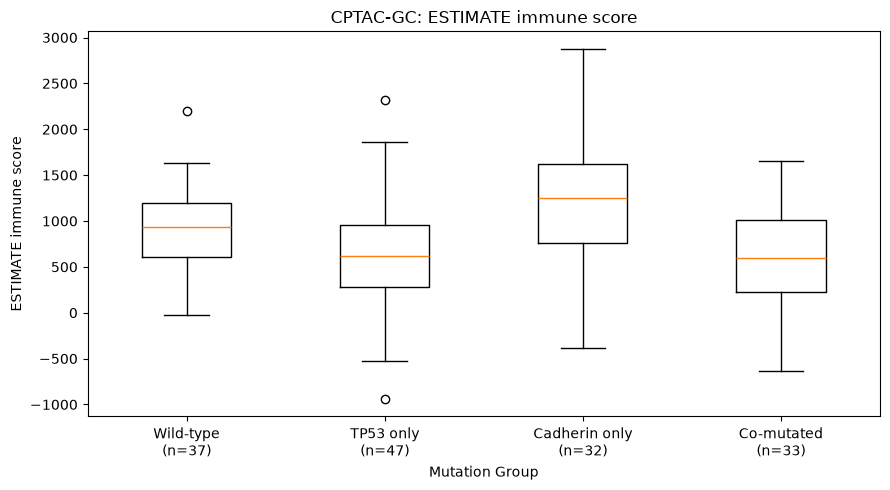

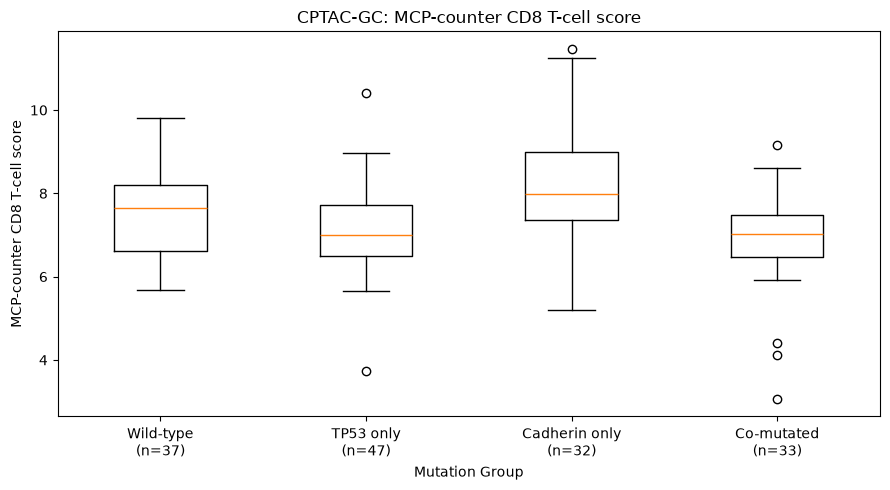

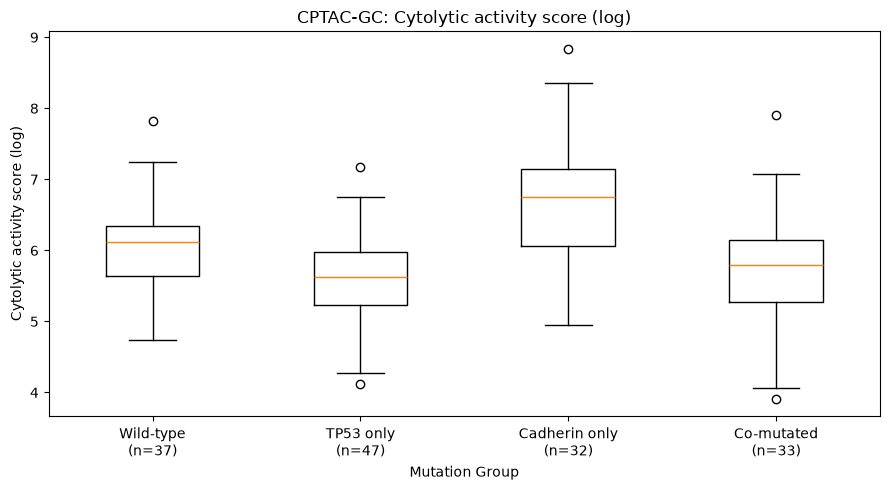

Figures saved in C:\Users\arz_2\BASIRA\Basira_Group_A\validation_data\New folder\CPTAC_Analysis


In [11]:
import matplotlib.pyplot as plt

groups = ["Wild-type", "TP53 only", "Cadherin only", "Co-mutated"]
scores_to_plot = {
    "ESTIMATE_Immune_Score": "ESTIMATE immune score",
    "CD8_Score":             "MCP-counter CD8 T-cell score",
    "CYT_log":               "Cytolytic activity score (log)",
}

for col, label in scores_to_plot.items():
    values = [d.loc[d["Mutation_Group"] == g, col].dropna() for g in groups]
    ticks  = [f"{g}\n(n={len(v)})" for g, v in zip(groups, values)]

    plt.figure(figsize=(9, 5))
    plt.boxplot(values, tick_labels=ticks)
    plt.title(f"CPTAC-GC: {label}")
    plt.xlabel("Mutation Group")
    plt.ylabel(label)
    plt.tight_layout()
    plt.savefig(output_dir / f"CPTAC_{col}_Final.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Figures saved in", output_dir.resolve())

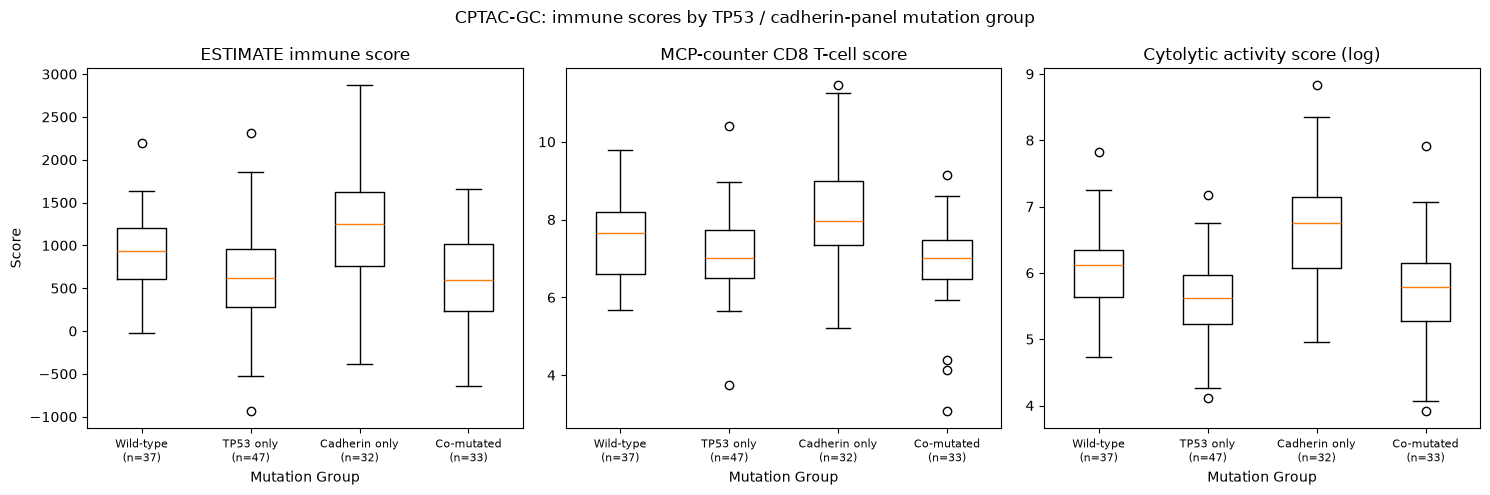

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, label) in zip(axes, scores_to_plot.items()):
    values = [d.loc[d["Mutation_Group"] == g, col].dropna() for g in groups]
    ax.boxplot(values, tick_labels=[f"{g}\n(n={len(v)})" for g, v in zip(groups, values)])
    ax.set_title(label)
    ax.set_xlabel("Mutation Group")
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Score")
fig.suptitle("CPTAC-GC: immune scores by TP53 / cadherin-panel mutation group")
plt.tight_layout()
plt.savefig(output_dir / "CPTAC_Figure1_combined.png", dpi=300, bbox_inches="tight")
plt.show()